

> **Pre-Processing**

This script provides a comprehensive text preprocessing pipeline tailored for Natural Language Processing (NLP) tasks. It begins by loading and deduplicating a dataset, then defines an extensive list of stop words, including common terms irrelevant to the analysis. Through a series of custom functions, the script cleans the text by removing emails, numbers, and punctuation, tokenizes it, and applies bigram and trigram phrase modeling to capture common multi-word expressions. The text is further lemmatized to reduce words to their base forms, and finally, stemming is applied to standardize word forms further. The processed text is stored in multiple stages (text, tokens, bigrams, lemmatized, and stemmed columns) within a DataFrame, enabling flexibility for different NLP model requirements.*italicized text*

In [1]:
import re
import numpy as np
import pandas as pd
import spacy
import gensim.corpora as corpora
from gensim.utils import simple_preprocess
from gensim.models.phrases import Phrases, Phraser
from gensim.parsing.porter import PorterStemmer
from pprint import pprint
from nltk.corpus import stopwords


import nltk
nltk.download('stopwords')
nlp = spacy.load('en_core_web_sm')


df = pd.read_excel('/content/Digital Twin.xlsx', index_col=0)
df = df.drop_duplicates(subset='Abstract', keep='first').reset_index(drop=True)

stop_words = stopwords.words('english')
stop_words.extend(['method', 'system', 'say', 'claim', 'wherein', 'device', 'apparatus', 'one', 'id', 'least',
                         'infomration', 'models', 'derivative', 'thereon', 'using', 'two', 'based', 'add', 'additional',
                         'also', 'well', 'include', 'including', 'however', 'first', 'second', 'method', 'methodology',
                         'level', 'datum', 'model', 'models', 'modeling', 'energy', 'power', 'respectively', 'process',
                         'base', 'used', 'uses', 'well', 'datum', 'novelty', 'use', 'draw', 'drawing', 'high', 'end',
                         'provides', 'provider', 'providers', 'unit', 'data', 'study', 'problem', 'base', 'examines',
                         'relevant', 'application', 'propose', 'survey', 'practice', 'theoretical', 'project', 'journal',
                         'challenge', 'factor', 'concept', 'method', 'methodology', 'increase', 'decrease', 'increasing',
                         'decreasing', 'support', 'influence', 'field', 'from', 'active', 'question', 'present', 'highly',
                         'issue', 'challenge', 'challenges', 'method', 'variable', 'investigate', 'impact', 'provide',
                         'find', 'finding', 'determination', 'determine', 'understand', 'subject', 'provide', 're',
                         'address', 'edu', 'study', 'implement', 'implementation', 'studies', 'however', 'improve',
                         'improvement', 'identify', 'theory', 'role', 'identification', 'identifying', 'identified',
                         'different', 'result', 'results', 'examine', 'find', 'use', 'paper', 'article', 'main', 'purpose',
                         'review', 'application', 'discussion', 'including', 'includs', 'paper', 'specify', 'focus',
                         'approach', 'literature', 'elsevier', 'analysis', 'framework', 'conclusion', 'analyze', 'rate',
                         'increasing', 'increase', 'indicator', 'individual', 'increased', 'measuring', 'measure',
                         'right', 'reserved', 'associate', 'measuring', 'differ', 'different', 'compare', 'comparing',
                         'variable', 'year', 'time', 'characteristic', 'test', 'china', 'chines', 'contribution', 'insight',
                         'identifi', 'includ', 'design', 'perspective', 'context', 'different', 'discuss', 'initial',
                         'discussion', 'author', 'authors', 'including', 'includes', 'consideration', 'show', 'shows',
                         'found', 'effect', 'affect', 'effects', 'impact', 'aim', 'reserch', 'study', 'analysis',
                         'literature review', 'theoretical framework', 'research question', 'methodology', 'findings',
                         'discussion', 'implications', 'theoretical contributions', 'empirical evidence', 'research gap',
                         'research agenda', 'quantitative', 'qualitative', 'case study', 'survey', 'empirical', 'analysis',
                         'modeling', 'framework', 'methodology', 'measurement', 'evaluation', 'data collection',
                         'research design', 'hypothesis', 'statistical analysis', 'implement', 'numerous', 'lessons',
                         'involve', 'make', 'agenda', 'highlight', 'nevertheless', 'play', 'influence', 'create', 'use',
                         'maker', 'utilise', 'follow', 'change', 'futur', 'related', 'area', 'research', 'science',
                         'systematic', 'academic', 'practitioner', 'topic', 'trend', 'consider', 'object', 'current',
                         'content', 'analytical', 'key', 'public', 'important', 'exist', 'work', 'map', 'direct', 'set',
                         'resulting', 'obtained', 'designed', 'obtaining', 'gain', 'suggesting', 'suggested', 'certain',
                         'reveal', 'revealing', 'determined', 'determining', 'achieve', 'achieving', 'establish',
                         'established', 'determine', 'examined', 'examining', 'considered', 'considering', 'importantly',
                         'indicate', 'indicated', 'showed', 'showing', 'evaluated', 'evaluating', 'proposed', 'proposing',
                         'implemented', 'implementing', 'various', 'especially', 'including', 'include', 'examines',
                         'examined', 'example', 'particular', 'according', 'accordance', 'follows', 'followed',
                         'illustrated', 'illustrate', 'represented', 'represent', 'represents', 'representing',
                         'highlighted', 'highlight', 'briefly', 'important', 'importance', 'significantly', 'significant',
                         'common', 'comparatively', 'generally', 'general', 'specific', 'especially', 'particularly',
                         'particular', 'distinct', 'differentiate', 'different', 'known', 'well-known', 'acknowledge',
                         'acknowledged', 'acknowledging', 'consideration', 'considering', 'consider', 'examining',
                         'examines', 'considered', 'focus', 'focusing', 'focused', 'highlight', 'highlighting',
                         'highlighted', 'analyze', 'analyzing', 'analyzed', 'analyze', 'clarified', 'clarify',
                         'clarifying', 'elaborate', 'elaborating', 'elaborated', 'discussed', 'discussing', 'discusses',
                         'discussion', 'discuss', 'evaluate', 'evaluating', 'evaluated', 'evaluate', 'examine', 'examining',
                         'examined', 'examine', 'explore', 'exploring', 'explored', 'explore', 'identify', 'identifying',
                         'identified', 'identify', 'illustrate', 'illustrating', 'illustrated', 'illustrate',
                         'investigate', 'investigating', 'investigated', 'investigate', 'observe', 'observing', 'observed',
                         'observe', 'outline', 'outlining', 'outlined', 'outline', 'present', 'presenting', 'presented',
                         'present', 'propose', 'proposing', 'proposed', 'propose', 'recognize', 'recognizing',
                         'recognized', 'recognize', 'show', 'showing', 'shown', 'show', 'speculate', 'speculating',
                         'speculated', 'speculate', 'suggest', 'suggesting', 'suggested', 'suggest'])


def clean_text(text):
    ## Remove emails, numbers, and punctuation
    text = re.sub(r'\S*@\S*\s?', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    # Lowercase the text
    text = text.lower()
    # Remove new line characters
    text = re.sub(r'\s+', ' ', text)
    # Remove distracting single quotes
    text = re.sub(r"\'", "", text)
    return text

def tokenize(text):
    tokens = simple_preprocess(text, deacc=True, min_len=3)
    return [token for token in tokens if token not in stop_words]

def make_bigrams(texts):
    bigram = Phrases(texts, min_count=10, threshold=50)
    bigram_phraser = Phraser(bigram)
    trigram = Phrases(bigram_phraser[texts], min_count=10, threshold=50)
    trigram_phraser = Phraser(trigram)
    return [trigram_phraser[bigram_phraser[doc]] for doc in texts]

def lemmatize(text, allowed_postags=['NOUN', 'VERB', 'ADJ', 'ADV']):
    doc = nlp(text)
    return [token.lemma_ for token in doc if token.pos_ in allowed_postags and token.lemma_ not in stop_words]

def stem(text):
    p = PorterStemmer()
    return [p.stem(token) for token in text]

df['text'] = df['Abstract'].apply(clean_text)
df['tokens'] = df['text'].apply(tokenize)
df['bigrams'] = make_bigrams(df['tokens'])
df['lemmatized'] = df['bigrams'].apply(lambda x: lemmatize(' '.join(x)))
df['stemmed'] = df['lemmatized'].apply(stem)




[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.



> **Bag-of-word**

This code prepares a Bag-of-Words (BoW) corpus for topic modeling by first extracting stemmed tokens from a DataFrame into a list of lists. It creates a Gensim Dictionary, mapping each unique word to an integer ID. To focus on meaningful terms, it filters out rare words (those appearing in fewer than 2 documents) and very common words (those in more than 70% of documents). Finally, it converts each document into a BoW format, where each document is represented as a list of (word ID, frequency) tuples. This filtered BoW corpus and dictionary are now optimized for efficient and relevant topic modeling.

In [2]:
import gensim

text = df['stemmed'].tolist()
dictionary = gensim.corpora.Dictionary(text)
print('Total Vocabulary Size:', len(dictionary))
dictionary.filter_extremes(no_below=2, no_above=0.7)
print('Total Vocabulary Size after removing:', len(dictionary))
corpus = [dictionary.doc2bow(t) for t in text]

Total Vocabulary Size: 14270
Total Vocabulary Size after removing: 6768


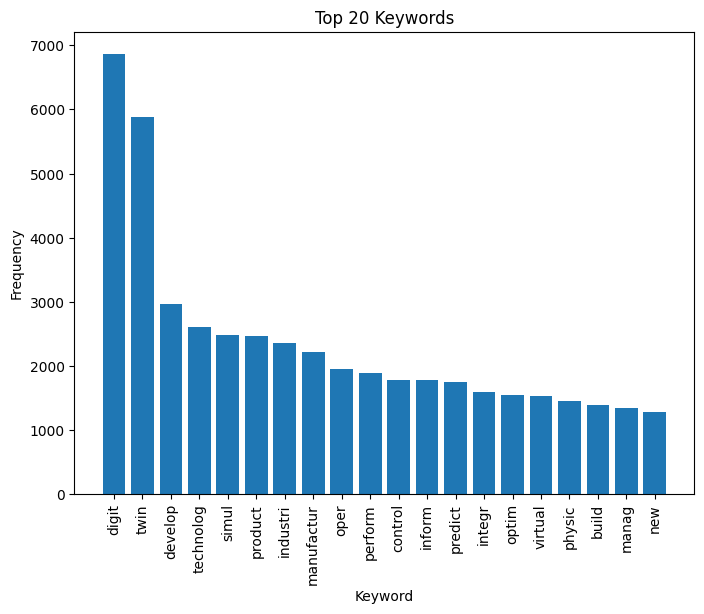

In [3]:
from collections import Counter
import matplotlib.pyplot as plt
word_list_flattened = [word for sublist in text for word in sublist]
word_counts = Counter(word_list_flattened)
top_keywords = word_counts.most_common(20)
# Create a bar chart of the top keywords
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar([x[0] for x in top_keywords], [x[1] for x in top_keywords])
ax.set_title('Top 20 Keywords')
ax.set_xlabel('Keyword')
ax.set_ylabel('Frequency')
plt.xticks(rotation=90)
plt.show()



> **Train initial LDA Model**

This code trains an LDA (Latent Dirichlet Allocation) model with 10 topics on a preprocessed Bag-of-Words corpus, using Gensim. It initializes the model with the specified corpus and dictionary and then iterates over each topic to display the top 10 words associated with it. For each topic, only the terms are shown, excluding their weights, providing a quick summary of the most representative words that define each topic. This model can then be used for tasks like topic classification and thematic exploration of the corpus.

In [4]:
import gensim
#اول باید مدل ترین بشه و  بعد تعداد تاپیک در بیاد. اینجا عدد فرضی 10 گذاشته شده تا کد رو بسازیم
num_topics = 10
lda_model = gensim.models.ldamodel.LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics)
for i, topic in lda_model.show_topics(num_topics=num_topics, num_words=10, formatted=False):
    print('Topic {}: {}'.format(i, [word[0] for word in topic]))


Topic 0: ['simul', 'optim', 'predict', 'robot', 'perform', 'technolog', 'virtual', 'train', 'dynam', 'function']
Topic 1: ['product', 'manufactur', 'develop', 'industri', 'simul', 'perform', 'optim', 'robot', 'oper', 'physic']
Topic 2: ['develop', 'simul', 'oper', 'industri', 'technolog', 'virtual', 'inform', 'network', 'perform', 'physic']
Topic 3: ['network', 'industri', 'develop', 'technolog', 'product', 'manag', 'perform', 'integr', 'solut', 'structur']
Topic 4: ['manufactur', 'technolog', 'product', 'industri', 'integr', 'inform', 'oper', 'develop', 'new', 'control']
Topic 5: ['develop', 'oper', 'predict', 'perform', 'structur', 'temperatur', 'mainten', 'technolog', 'engin', 'sustain']
Topic 6: ['simul', 'paramet', 'control', 'structur', 'perform', 'predict', 'develop', 'industri', 'oper', 'materi']
Topic 7: ['manufactur', 'optim', 'product', 'simul', 'vibrat', 'develop', 'technolog', 'estim', 'cost', 'predict']
Topic 8: ['develop', 'technolog', 'industri', 'case', 'requir', 'opti



> **Identifying Optimum Number of Topics**
This code explores different numbers of topics for an LDA model, evaluating each based on coherence and perplexity scores to identify the optimal number of topics. It iterates through a specified range of topics (2 to 29 in this case), training an LDA model for each topic count and calculating coherence (a measure of topic quality) and perplexity (a measure of model fit). Coherence and perplexity scores are stored and plotted for visualization. The optimal number of topics is determined by finding the highest coherence score within a defined threshold (95% of the maximum coherence) and the lowest perplexity score. The optimal topic count is highlighted on the plot, allowing for a clear visual assessment of the balance between coherence and perplexity across topic counts.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Number of topics: 2
Coherence score: 0.37588615608873566
Perplexity score: -7.320637414783426

Number of topics: 3
Coherence score: 0.4131393841061131
Perplexity score: -7.308056835707893

Number of topics: 4
Coherence score: 0.402152506047758
Perplexity score: -7.297793012762109

Number of topics: 5
Coherence score: 0.4521448631778565
Perplexity score: -7.308150655445968

Number of topics: 6
Coherence score: 0.43805942717213914
Perplexity score: -7.320629143961015

Number of topics: 7
Coherence score: 0.4092098623864257
Perplexity score: -7.320764824629033

Number of topics: 8
Coherence score: 0.387451580619369
Perplexity score: -7.323262578261379

Number of topics: 9
Coherence score: 0.3948777984438279
Perplexity score: -7.337808214545665

Number of topics: 10
Coherence score: 0.42080920470356276
Perplexity score: -7.391902169207024

Number of topics: 11
Coherence score: 0.3915543415966164
Perplexity score: -7.535752984052998

Number of topics: 12
Coherence score: 0.403972998489785
P

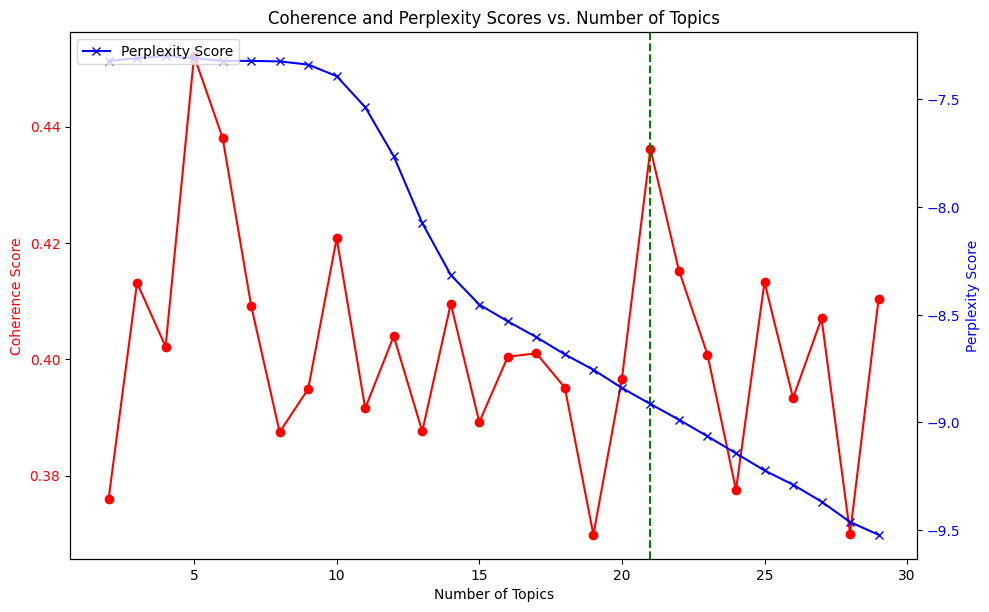

In [138]:

topic_range = list(range(2, 30, 1))  # You can adjust this range as needed
# Initialize variables to store coherence and perplexity scores
best_coherence_score = -1  # Highest coherence seen so far
best_perplexity_score = float('inf')  # Lowest perplexity seen within the coherence threshold
optimal_num_topics = -1  # Optimal number of topics based on the new criteria
coherence_threshold_factor = 0.95  # Define a factor to allow coherence within 5% of the max


coherence_scores = []
perplexity_scores = []

for num_topics in topic_range:
    # Train the LDA model
    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=100,
        chunksize=500,
        passes=20,
        alpha='auto',
        per_word_topics=True
    )


    coherence_model_lda = CoherenceModel(model=lda_model, texts=text, dictionary=dictionary, coherence='c_v')
    coherence_score = coherence_model_lda.get_coherence()
    coherence_scores.append(coherence_score)


    perplexity_score = lda_model.log_perplexity(corpus)
    perplexity_scores.append(perplexity_score)


    print(f"Number of topics: {num_topics}")
    print(f"Coherence score: {coherence_score}")
    print(f"Perplexity score: {perplexity_score}\n")


    if coherence_score > best_coherence_score:
        best_coherence_score = coherence_score


coherence_threshold = best_coherence_score * coherence_threshold_factor


for i, num_topics in enumerate(topic_range):
    coherence_score = coherence_scores[i]
    perplexity_score = perplexity_scores[i]


    if coherence_score >= coherence_threshold and perplexity_score < best_perplexity_score:
        best_perplexity_score = perplexity_score
        optimal_num_topics = num_topics


print(f'Optimal number of topics: {optimal_num_topics} (Max Coherence Threshold: {coherence_threshold}, Min Perplexity: {best_perplexity_score})')

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(topic_range, coherence_scores, label='Coherence Score', marker='o', color='red')
ax1.set_xlabel('Number of Topics')
ax1.set_ylabel('Coherence Score', color='red')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.plot(topic_range, perplexity_scores, label='Perplexity Score', marker='x', color='blue')
ax2.set_ylabel('Perplexity Score', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

if optimal_num_topics != -1:
    ax1.axvline(optimal_num_topics, linestyle='--', color='green', label=f'Optimal Topics: {optimal_num_topics}')

fig.tight_layout()
plt.title('Coherence and Perplexity Scores vs. Number of Topics')
plt.legend(loc='upper left')
plt.show()




> **Train LDA Model**

This code trains an LDA (Latent Dirichlet Allocation) model with a predefined optimal number of topics (21) on a given corpus and dictionary, then saves the trained model to disk. lda_model is initialized with various hyperparameters, including random_state for reproducibility and alpha='auto' for automatic tuning of the topic distribution. After training, the code verifies the number of topics in the model and saves it to lda_model_optimal_topics.model, allowing for easy reuse or analysis of the model without retraining.

In [147]:
lda_model = LdaModel(corpus=corpus,
                     id2word=dictionary,
                     num_topics=21,
                     random_state=100,
                     chunksize=500,
                     passes=20,
                     alpha=0.3,
                     per_word_topics=True)
for topic in lda_model.print_topics():
    print(topic)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


(17, '0.022*"flow" + 0.021*"optim" + 0.018*"temperatur" + 0.016*"perform" + 0.016*"simul" + 0.014*"reduc" + 0.014*"cost" + 0.010*"low" + 0.010*"thermal" + 0.010*"experiment"')
(1, '0.025*"inform" + 0.023*"vehicl" + 0.017*"infrastructur" + 0.014*"urban" + 0.014*"citi" + 0.014*"traffic" + 0.009*"potenti" + 0.009*"commun" + 0.009*"attack" + 0.009*"transport"')
(10, '0.051*"materi" + 0.041*"assembl" + 0.037*"qualiti" + 0.034*"part" + 0.032*"paramet" + 0.023*"mechan" + 0.020*"composit" + 0.016*"predict" + 0.015*"defect" + 0.015*"optim"')
(20, '0.097*"machin" + 0.050*"schedul" + 0.035*"predict" + 0.024*"forecast" + 0.022*"ship" + 0.019*"deviat" + 0.019*"error" + 0.018*"event" + 0.018*"monitor" + 0.017*"mill"')
(16, '0.082*"network" + 0.030*"servic" + 0.025*"resourc" + 0.025*"distribut" + 0.021*"commun" + 0.017*"optim" + 0.016*"metavers" + 0.016*"comput" + 0.014*"architectur" + 0.014*"effici"')
(13, '0.039*"train" + 0.022*"perform" + 0.022*"detect" + 0.021*"gener" + 0.021*"machine_learn" + 0.

In [148]:
topics = [[(term, round(wt, 3)) for term, wt in lda_model.show_topic(n, topn=25)] for n in range(0, lda_model.num_topics)]
topics

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


[[('control', 0.058),
  ('dynam', 0.036),
  ('virtual', 0.029),
  ('realtim', 0.025),
  ('physic', 0.025),
  ('simul', 0.025),
  ('space', 0.024),
  ('predict', 0.022),
  ('mechan', 0.015),
  ('optim', 0.014),
  ('effect', 0.014),
  ('complex', 0.013),
  ('perform', 0.013),
  ('real', 0.012),
  ('experi', 0.011),
  ('interact', 0.01),
  ('verifi', 0.01),
  ('drive', 0.01),
  ('accuraci', 0.01),
  ('equip', 0.009),
  ('final', 0.009),
  ('oper', 0.008),
  ('realiz', 0.008),
  ('actual', 0.008),
  ('mine', 0.008)],
 [('inform', 0.025),
  ('vehicl', 0.023),
  ('infrastructur', 0.017),
  ('urban', 0.014),
  ('citi', 0.014),
  ('traffic', 0.014),
  ('potenti', 0.009),
  ('commun', 0.009),
  ('attack', 0.009),
  ('transport', 0.009),
  ('road', 0.008),
  ('secur', 0.008),
  ('environ', 0.008),
  ('scenario', 0.007),
  ('futur', 0.007),
  ('mobil', 0.007),
  ('develop', 0.007),
  ('camera', 0.007),
  ('sensor', 0.007),
  ('video', 0.006),
  ('view', 0.006),
  ('domain', 0.006),
  ('capabl', 0

In [149]:
topics_df = pd.DataFrame([[term for term, wt in topic] for topic in topics], columns = ['Term'+str(i) for i in range(1, 26)],
                         index=['Topic '+str(t) for t in range(1, lda_model.num_topics+1)]).T
topics_df.head()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10,...,Topic 12,Topic 13,Topic 14,Topic 15,Topic 16,Topic 17,Topic 18,Topic 19,Topic 20,Topic 21
Term1,control,inform,build,sustain,oper,technolog,structur,paramet,electr,simul,...,product,patient,train,knowledg,robot,network,flow,virtual,configur,machin
Term2,dynam,vehicl,construct,technolog,develop,human,sensor,distribut,cell,engin,...,manufactur,dt,perform,learn,task,servic,optim,interact,cp,schedul
Term3,virtual,infrastructur,manag,develop,plant,industri,imag,surfac,batteri,develop,...,industri,treatment,detect,educ,program,resourc,temperatur,softwar,reconfigur,predict
Term4,realtim,urban,inform,innov,water,new,estim,estim,capac,comput,...,smart,predict,gener,blockchain,environ,distribut,perform,develop,teach,forecast
Term5,physic,citi,integr,social,mainten,intellig,monitor,particl,load,valid,...,develop,clinic,machine_learn,technolog,modul,commun,simul,user,bodi,ship


This code creates a DataFrame that summarizes the top terms for each topic in a trained LDA model. Each topic's top terms are extracted and joined into a single string, making them easy to read and interpret in the DataFrame. The resulting DataFrame (topics_df) has rows labeled by topic (e.g., "Topic 1", "Topic 2", etc.) and a single column, "Terms per Topic," that contains a comma-separated list of the most representative terms for each topic. Finally, pd.set_option('display.max_colwidth', None) ensures that long strings of terms are fully visible when displayed, rather than being truncated.

In [150]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

topics_df = pd.DataFrame(
    [', '.join([term for term, wt in topic]) for topic in topics],
    columns=['Terms per Topic'],
    index=['Topic ' + str(t) for t in range(1, lda_model.num_topics + 1)]
)

topics_df


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Terms per Topic
Topic 1,"control, dynam, virtual, realtim, physic, simul, space, predict, mechan, optim, effect, complex, perform, real, experi, interact, verifi, drive, accuraci, equip, final, oper, realiz, actual, mine"
Topic 2,"inform, vehicl, infrastructur, urban, citi, traffic, potenti, commun, attack, transport, road, secur, environ, scenario, futur, mobil, develop, camera, sensor, video, view, domain, capabl, avail, semant"
Topic 3,"build, construct, manag, inform, integr, safeti, bim, visual, technolog, mainten, monitor, plan, intellig, risk, decisionmak, site, structur, facil, assess, asset, develop, action, effici, case, effect"
Topic 4,"sustain, technolog, develop, innov, social, econom, valu, futur, organ, transform, benefit, opportun, sector, potenti, goal, growth, urban, gap, busi, environment, global, economi, govern, strategi, assess"
Topic 5,"oper, develop, plant, water, mainten, heat, monitor, market, continu, tool, effici, control, save, mode, resili, state, transit, condit, sensor, reduc, reliabl, facil, climat, equip, demand"
Topic 6,"technolog, human, industri, new, intellig, world, emerg, advanc, artificial_intellig, autom, develop, futur, integr, light, becom, environ, parallel, virtual, agent, autonom, worker, introduc, activ, scientif, cognit"
Topic 7,"structur, sensor, imag, estim, monitor, predict, damag, signal, accuraci, reconstruct, accur, condit, perform, bridg, inspect, load, segment, track, detect, respons, local, stress, compon, posit, demonstr"
Topic 8,"paramet, distribut, surfac, estim, particl, variat, optic, sensit, valu, fiber, accur, sourc, error, comput, sampl, experiment, microstructur, contact, depend, dynam, perform, densiti, volum, convent, equat"
Topic 9,"electr, cell, batteri, capac, load, degrad, recoveri, charg, grid, ag, profil, behavior, constant, pair, genet, correl, heart, estim, voltag, environment, radiat, ergonom, fractur, assess, resource_alloc"
Topic 10,"simul, engin, develop, comput, valid, demonstr, case, requir, tool, gener, real, integr, perform, control, scenario, complex, physic, need, dynam, capabl, procedur, uncertainti, optimis, model, enabl"




> **Word Cloud**

This code generates and displays word clouds for each topic in an LDA model, where each word cloud highlights the most prominent terms for that topic. It initializes the WordCloud object with parameters like background_color and colormap for aesthetic control. The figure's layout is dynamically calculated based on the total number of topics (num_topics) to ensure all word clouds fit neatly into a grid with 4 columns. Each topic's terms are passed to wc.generate() to create a unique word cloud, and each cloud is displayed as a subplot in the grid. This visualization provides an intuitive, visually appealing way to understand the main terms associated with each topic.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
<ipython-input-143-6c205616bcbd>:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wc.generate(text=topics_df["Terms per Topic"][i])


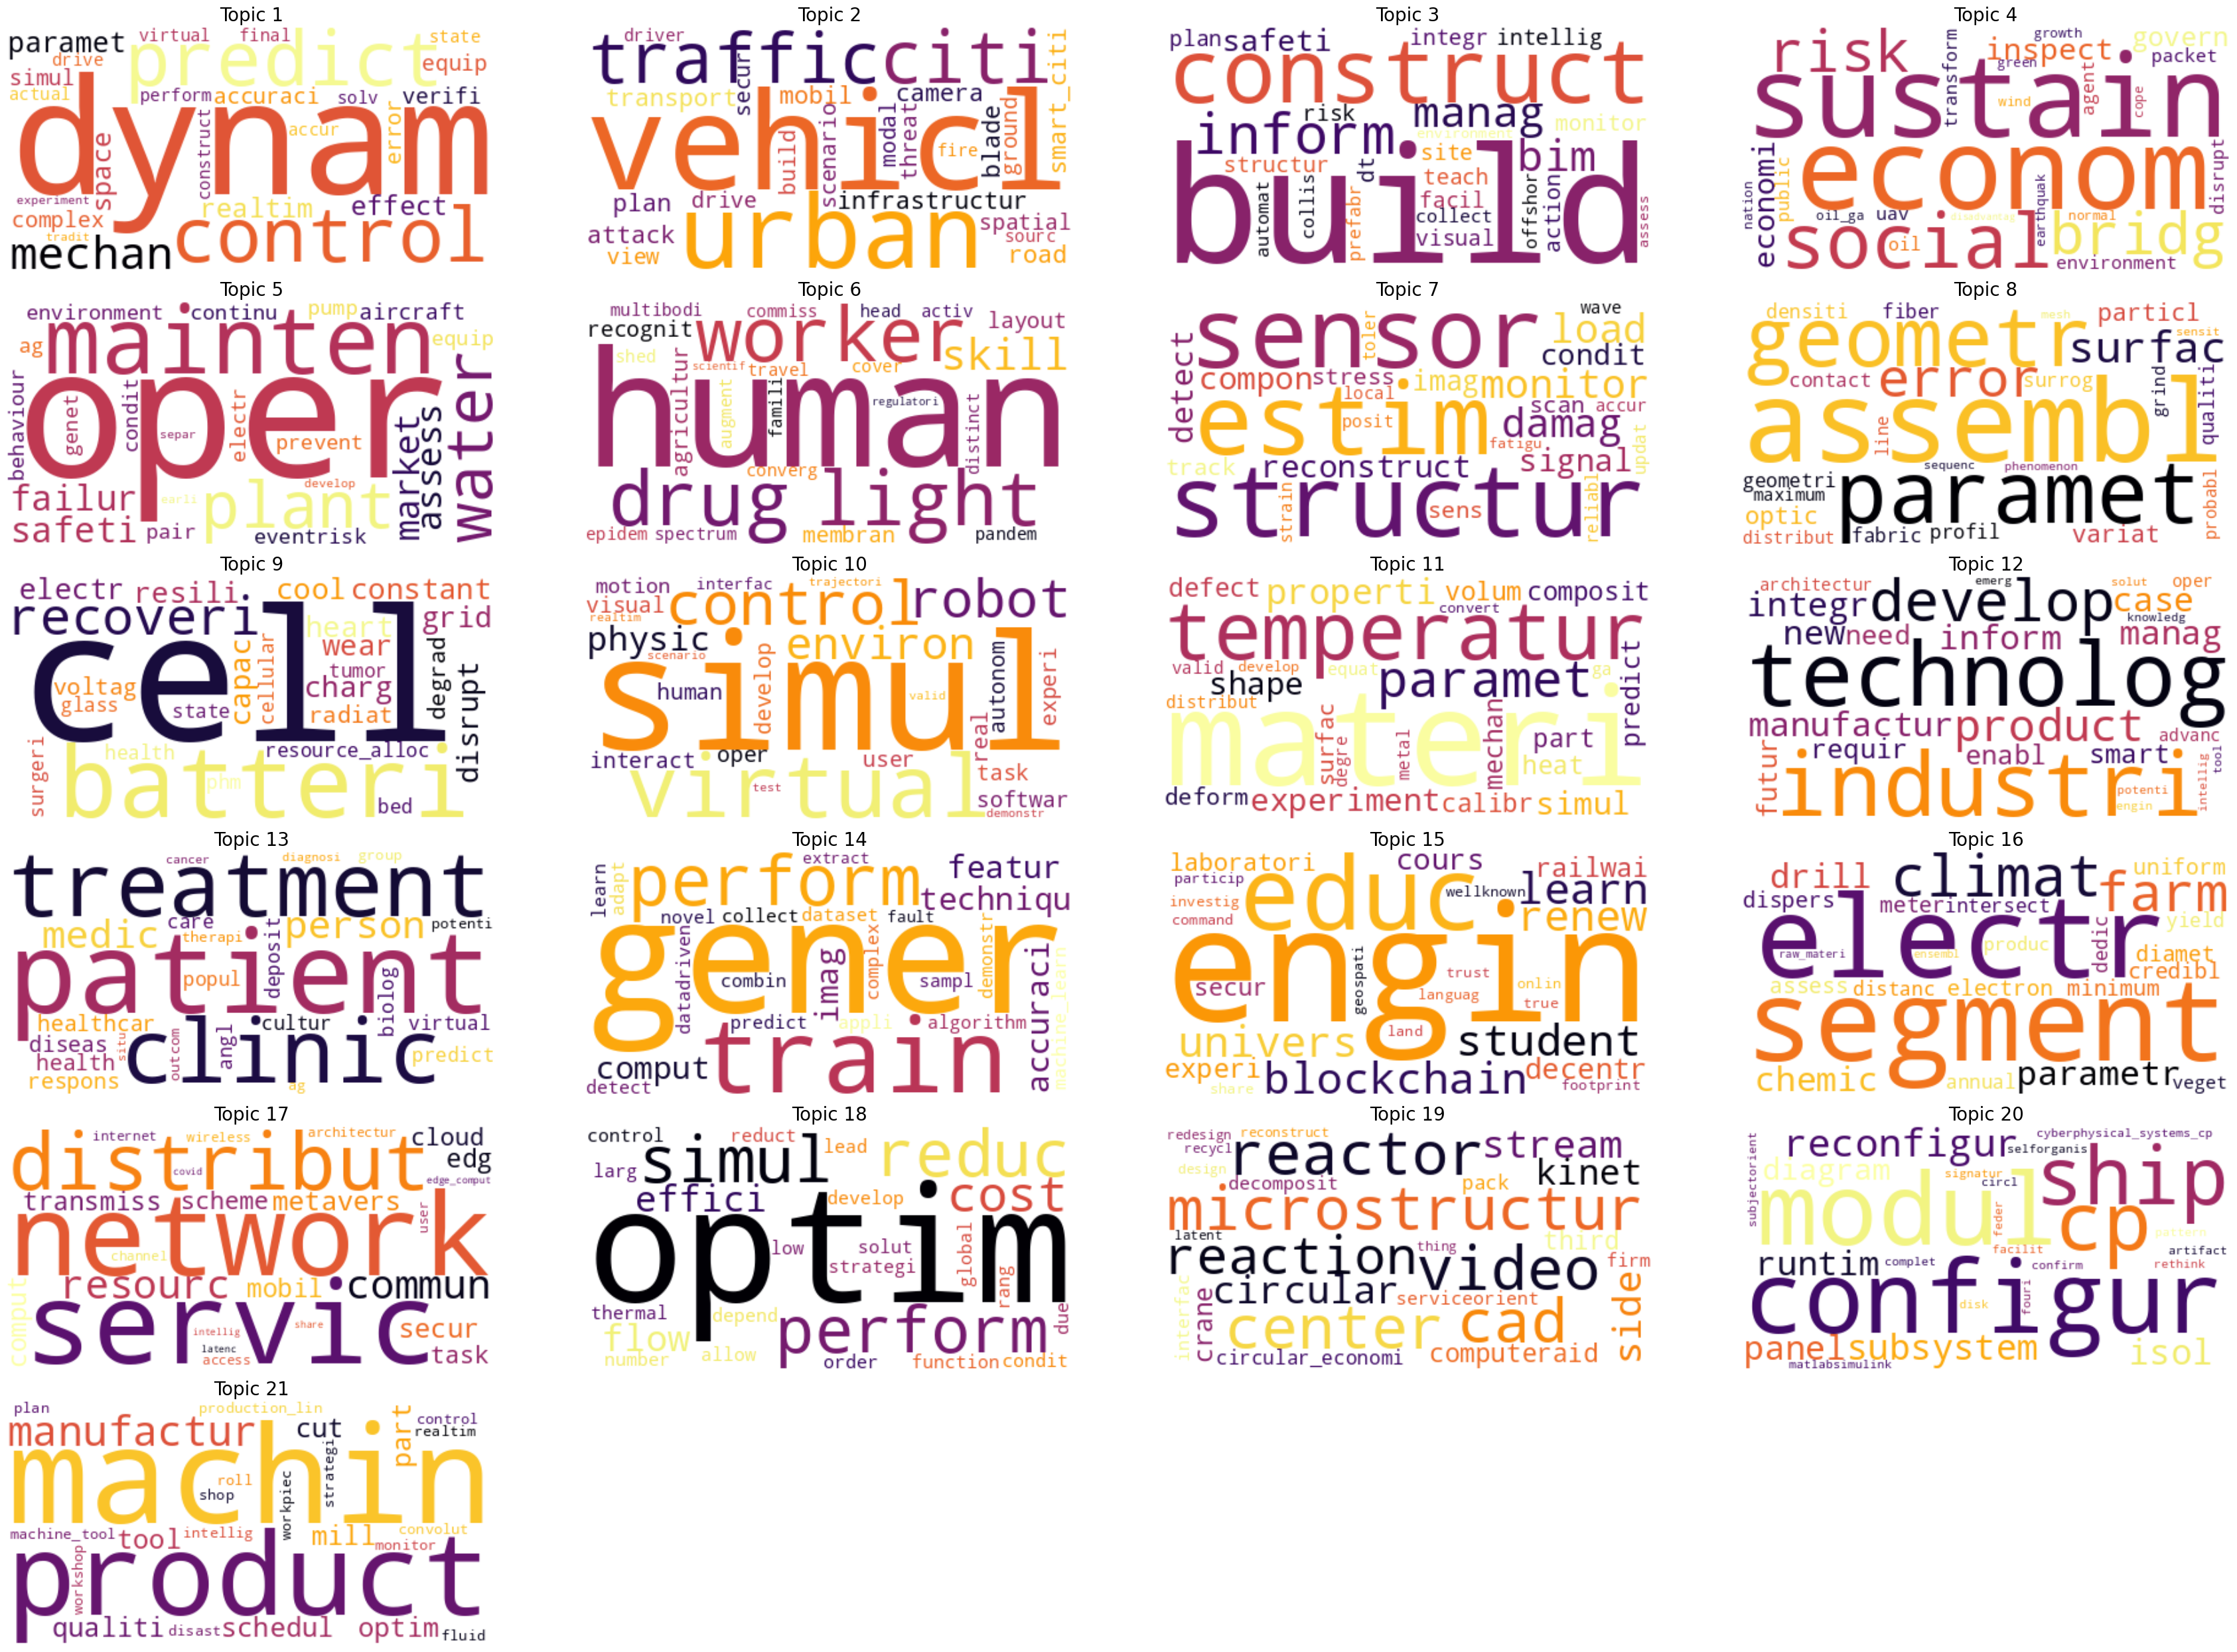

In [143]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(background_color="white", colormap="inferno",
               max_font_size=150, random_state=30)

plt.rcParams['figure.figsize'] = [35, 25]

num_topics = len(topics_df)
cols = 4
rows = (num_topics + cols - 1) // cols

for i in range(num_topics):

    wc.generate(text=topics_df["Terms per Topic"][i])


    plt.subplot(rows, cols, i + 1)
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(topics_df.index[i], fontsize=20)

plt.tight_layout()
plt.show()




> **Term per Topic Visualization**

This code checks the topics retrieved from a trained LDA model and, if necessary, retrieves the topic-term matrix directly to ensure all topics are accounted for. Initially, it prints the number of topics and retrieves the top terms for each topic using show_topics(). If fewer topics are returned than expected, it falls back on get_topics(), which provides the full topic-term matrix.

The code then extracts the top 5 words for each topic by sorting the term weights in descending order. It uses these top terms and their weights to plot histograms, showing the distribution of term weights for each topic. The layout is dynamically adjusted based on the number of topics, displaying the histograms in a grid format with 5 columns and enough rows to accommodate all topics. Each bar in the histogram is assigned a unique color for easy differentiation, and the result provides a clear visual representation of the most significant words for each topic in the model.



/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap("tab20", num_words)(range(num_words))
<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap("tab20", num_words)(range(num_words))
<ipython-input-

Number of topics in the model: 21
Retrieved topics: 10 topics
Topic 1: (19, [('configur', 0.1699972), ('modul', 0.14628008), ('ship', 0.08984411), ('cp', 0.070344284), ('reconfigur', 0.06903952)])
Topic 2: (15, [('segment', 0.07438255), ('electr', 0.04314544), ('climat', 0.03876641), ('farm', 0.03405476), ('parametr', 0.032365195)])
Topic 3: (8, [('cell', 0.079527706), ('batteri', 0.07614877), ('recoveri', 0.03946681), ('charg', 0.038315337), ('resili', 0.036111422)])
Topic 4: (5, [('human', 0.08812355), ('light', 0.054208755), ('drug', 0.0442858), ('worker', 0.040700104), ('skill', 0.037802186)])
Topic 5: (3, [('sustain', 0.16194087), ('econom', 0.0718114), ('social', 0.061675835), ('bridg', 0.04193966), ('risk', 0.04074209)])
Topic 6: (9, [('simul', 0.045181066), ('virtual', 0.044259995), ('control', 0.0417883), ('robot', 0.041707087), ('environ', 0.03144992)])
Topic 7: (0, [('dynam', 0.047728732), ('predict', 0.04257255), ('control', 0.024863113), ('mechan', 0.024612248), ('paramet'

<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap("tab20", num_words)(range(num_words))
<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap("tab20", num_words)(range(num_words))
<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap("tab20", num_words)(range(num_words))
<ipython-input-144-65ceddb07d26>:34: MatplotlibDeprecat

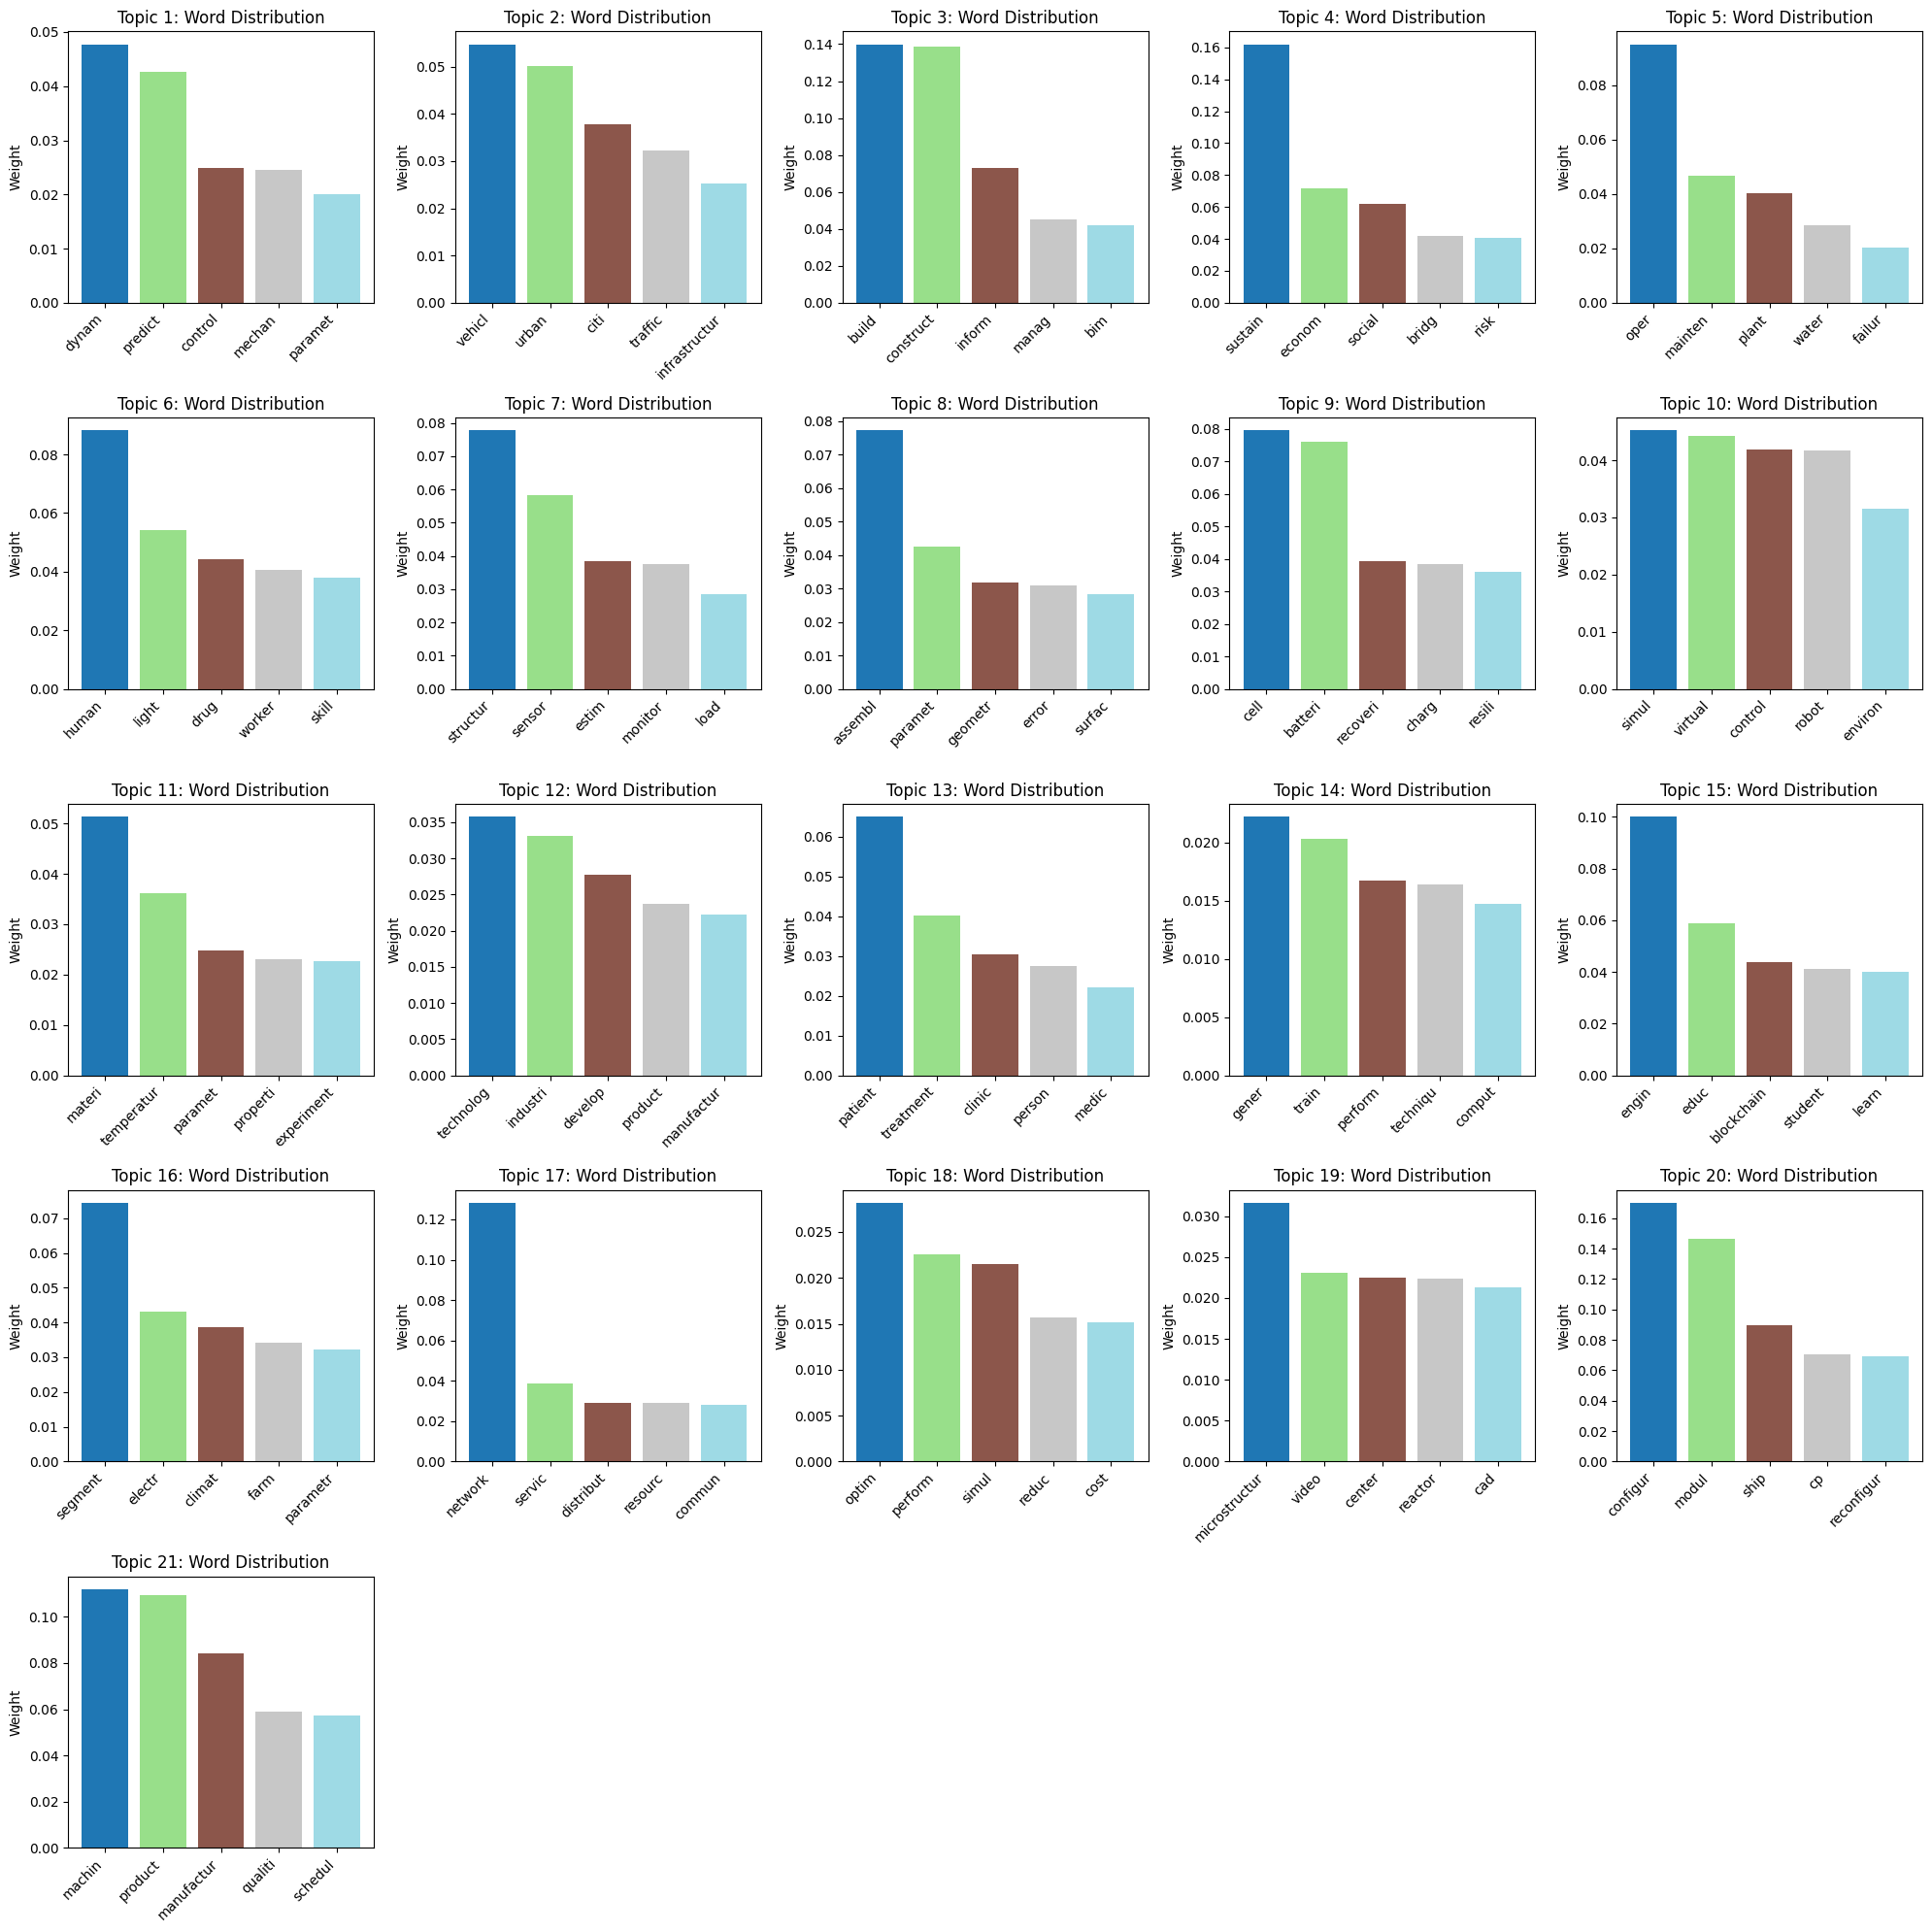

In [144]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
from gensim.models.ldamodel import LdaModel

print(f"Number of topics in the model: {lda_model.num_topics}")

topics = lda_model.show_topics(formatted=False, num_words=5)
print(f"Retrieved topics: {len(topics)} topics")
for i, topic in enumerate(topics):
    print(f"Topic {i + 1}: {topic}")

if len(topics) < lda_model.num_topics:
    print("show_topics() retrieved fewer topics than expected. Using get_topics() as an alternative.")


    topic_term_matrix = lda_model.get_topics()


    num_words = 5
    num_topics = lda_model.num_topics
    cols = 5
    rows = (num_topics + cols - 1) // cols


    terms = [lda_model.id2word[i] for i in range(len(lda_model.id2word))]  # Full vocabulary list
    top_terms = [[terms[i] for i in topic.argsort()[-num_words:][::-1]] for topic in topic_term_matrix]
    top_weights = [[topic[i] for i in topic.argsort()[-num_words:][::-1]] for topic in topic_term_matrix]


    plt.figure(figsize=(20, rows * 4))
    for i, (terms, weights) in enumerate(zip(top_terms, top_weights)):
        colors = cm.get_cmap("tab20", num_words)(range(num_words))
        ax = plt.subplot(rows, cols, i + 1)
        ax.bar(terms, weights, color=colors)
        ax.set_ylabel("Weight")
        ax.set_title(f"Topic {i + 1}: Word Distribution")
        plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()


In [151]:
import pandas as pd

# Create a list to store the dominant topics for each document
dominant_topics = []

# Loop through each document in the corpus
for i, doc in enumerate(corpus):
    # Get the dominant topic for the current document
    topic_probs = lda_model.get_document_topics(doc, minimum_probability=0.0)
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
    dominant_topics.append(dominant_topic)

# Create a Pandas dataframe containing the dominant topic for each document
df_dominant_topics = pd.DataFrame({'Dominant_Topic': dominant_topics})

# Concatenate the original dataset with the new dataframe
df_with_topics = pd.concat([df, df_dominant_topics], axis=1)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [152]:
import numpy as np
import pandas as pd

num_topics = lda_model.num_topics
dominant_topic_df = pd.DataFrame({'Dominant Topic': dominant_topics})
dominant_topic_counts = dominant_topic_df['Dominant Topic'].value_counts().reindex(range(num_topics), fill_value=0)
dominant_topic_df = pd.DataFrame({
    'Dominant Topic': dominant_topic_counts.index,
    'Doc_Count': dominant_topic_counts.values
})

dominant_topic_df['Total_Docs_Perc'] = dominant_topic_df['Doc_Count'].apply(lambda count: round((count * 100) / len(corpus), 2))

dominant_topic_df


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Dominant Topic,Doc_Count,Total_Docs_Perc
0,0,294,7.73
1,1,251,6.60
2,2,154,4.05
3,3,87,2.29
4,4,139,3.65
5,5,114,3.00
6,6,260,6.83
7,7,107,2.81
8,8,43,1.13
9,9,337,8.86


This code identifies the dominant topic for each document in a corpus based on an LDA model and saves the results to an Excel file. For each document, it retrieves the topic probabilities, selects the topic with the highest probability (i.e., the dominant topic), and stores the topic number along with its contribution percentage. The dominant topic and contribution are added as new columns to the original DataFrame df, creating a comprehensive view of each document's primary topic. Finally, the updated DataFrame is saved to an Excel file named Digital_Twin_with_Dominant_Topic.xlsx, allowing for easy access and further analysis of the topic modeling results.

In [125]:
import pandas as pd

dominant_topics = []


for doc in corpus:

    topic_probs = lda_model.get_document_topics(doc, minimum_probability=0.0)
    dominant_topic, contribution = max(topic_probs, key=lambda x: x[1])
    dominant_topics.append((dominant_topic, contribution))


df_dominant_topics = pd.DataFrame(dominant_topics, columns=['Dominant_Topic', 'Contribution %'])


df['Dominant_Topic'] = df_dominant_topics['Dominant_Topic']
df['Contribution %'] = df_dominant_topics['Contribution %']

df.to_excel('/content/Digital_Twin_with_Dominant_Topic.xlsx', sheet_name='UpdatedData')

print("Dominant topics and contributions have been added to the original DataFrame and saved to Excel.")


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Dominant topics and contributions have been added to the original DataFrame and saved to Excel.


In [126]:
import pandas as pd

dominant_topics = []

for doc in corpus:

    topic_probs = lda_model.get_document_topics(doc, minimum_probability=0.0)

    dominant_topics.append([contribution for _, contribution in topic_probs])

num_topics = lda_model.num_topics
df_weights = pd.DataFrame(dominant_topics, columns=['Topic ' + str(i + 1) for i in range(num_topics)])

print(df_weights)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


       Topic 1   Topic 2   Topic 3   Topic 4   Topic 5   Topic 6   Topic 7  \
0     0.016079  0.004175  0.003240  0.002275  0.006063  0.002266  0.006837   
1     0.098538  0.016757  0.001990  0.001372  0.003400  0.001366  0.004645   
2     0.035952  0.051636  0.003608  0.002527  0.029703  0.002516  0.007773   
3     0.025614  0.003295  0.002538  0.001779  0.298416  0.001774  0.135221   
4     0.273020  0.002689  0.062239  0.001459  0.003701  0.001454  0.022821   
...        ...       ...       ...       ...       ...       ...       ...   
3799  0.093783  0.002619  0.002013  0.013626  0.003767  0.014206  0.083249   
3800  0.184202  0.009269  0.001195  0.000837  0.069036  0.019671  0.122669   
3801  0.022292  0.026900  0.001603  0.001117  0.002898  0.026345  0.003630   
3802  0.095610  0.001900  0.001460  0.098385  0.384718  0.001021  0.017949   
3803  0.025099  0.013018  0.001639  0.001150  0.056454  0.011835  0.003773   

       Topic 8   Topic 9  Topic 10  ...  Topic 12  Topic 13  To

In [127]:
df_weights['Year'] = df.Year
df_weights.groupby('Year').mean()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8,Topic 9,Topic 10,...,Topic 12,Topic 13,Topic 14,Topic 15,Topic 16,Topic 17,Topic 18,Topic 19,Topic 20,Topic 21
Year,,,,,,,,,,,,,,,,,,,,,
2000,0.021054,0.043582,0.003145,0.002188,0.532151,0.002179,0.006759,0.004329,0.025593,0.040341,...,0.123737,0.084012,0.033830,0.002346,0.002014,0.003922,0.052886,0.003561,0.001453,0.003045
2002,0.051409,0.027458,0.003103,0.002167,0.230415,0.002158,0.016603,0.004160,0.002032,0.045901,...,0.238772,0.003288,0.166745,0.112651,0.001994,0.003836,0.064193,0.003503,0.001439,0.003014
2004,0.132250,0.004017,0.003056,0.002148,0.040182,0.002137,0.155332,0.124763,0.002013,0.044805,...,0.098592,0.003219,0.072264,0.002304,0.001976,0.003823,0.173519,0.028994,0.001426,0.002980
2005,0.046896,0.003373,0.002626,0.001835,0.419989,0.001827,0.006436,0.043326,0.022408,0.043756,...,0.155581,0.002779,0.143476,0.001967,0.001690,0.003262,0.085921,0.002969,0.001219,0.002552
2006,0.026537,0.059131,0.003541,0.022898,0.372102,0.002463,0.007485,0.004771,0.060005,0.024404,...,0.183657,0.052715,0.094032,0.002653,0.002277,0.004403,0.057210,0.004030,0.001643,0.003440
2007,0.025403,0.011613,0.019406,0.002038,0.467024,0.017149,0.055998,0.014143,0.006412,0.037467,...,0.091535,0.003074,0.102089,0.002185,0.001876,0.003610,0.124763,0.003297,0.001354,0.002830
2008,0.079036,0.129459,0.002594,0.043783,0.112342,0.008213,0.045042,0.019679,0.001705,0.091711,...,0.073330,0.009917,0.077158,0.014043,0.001673,0.003249,0.254813,0.003119,0.013547,0.009024
2009,0.020476,0.013883,0.003401,0.019005,0.160587,0.006995,0.062206,0.004594,0.006622,0.147518,...,0.154341,0.041860,0.069169,0.002561,0.002199,0.108398,0.142897,0.003901,0.001587,0.003318
2010,0.026903,0.038958,0.003612,0.026972,0.280725,0.002517,0.007639,0.004833,0.002370,0.040835,...,0.241117,0.003818,0.103449,0.002711,0.002327,0.004632,0.188653,0.004103,0.001679,0.003508


In [128]:

topic_trends = df_weights.groupby('Year').mean()
topic_trends.to_excel("topic_trends_over_time.xlsx", sheet_name="Topic Trends")
print("Data saved to topic_trends_over_time.xlsx")

Data saved to topic_trends_over_time.xlsx


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)




> **Cosine Similarity**

This code computes and visualizes the cosine similarity between topics in an LDA model, helping to identify relationships or overlaps among topics. First, it extracts the topic-word distributions from the trained LDA model, where each row represents a topic as a vector of word weights. Using these vectors, it calculates the cosine similarity matrix, which quantifies how similar each pair of topics is, with values closer to 1 indicating higher similarity.

The similarity matrix is then converted into a DataFrame for easy labeling, and finally, it is visualized as a heatmap using Seaborn. Each cell in the heatmap shows the cosine similarity between two topics, with a color gradient providing an intuitive representation of topic similarity. Darker colors (closer to red in a "coolwarm" colormap) indicate high similarity, while lighter colors (closer to blue) represent lower similarity.
How to Interpret


*   High Similarity (values near 1): Topics with high cosine similarity share many of the same high-weighted words, indicating they cover closely related themes. This may suggest redundancy or overlap between these topics.
*   Low Similarity (values near 0 or negative): Topics with low cosine similarity are distinct and focus on different sets of words, indicating unique themes in the dataset.
*   Diagonal Cells: The diagonal cells represent self-similarity (each topic compared to itself) and will always have a value of 1. These cells can be ignored in interpretation.

This visualization helps identify potential redundancies in the topic model and can inform decisions about merging or reinterpreting similar topics.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


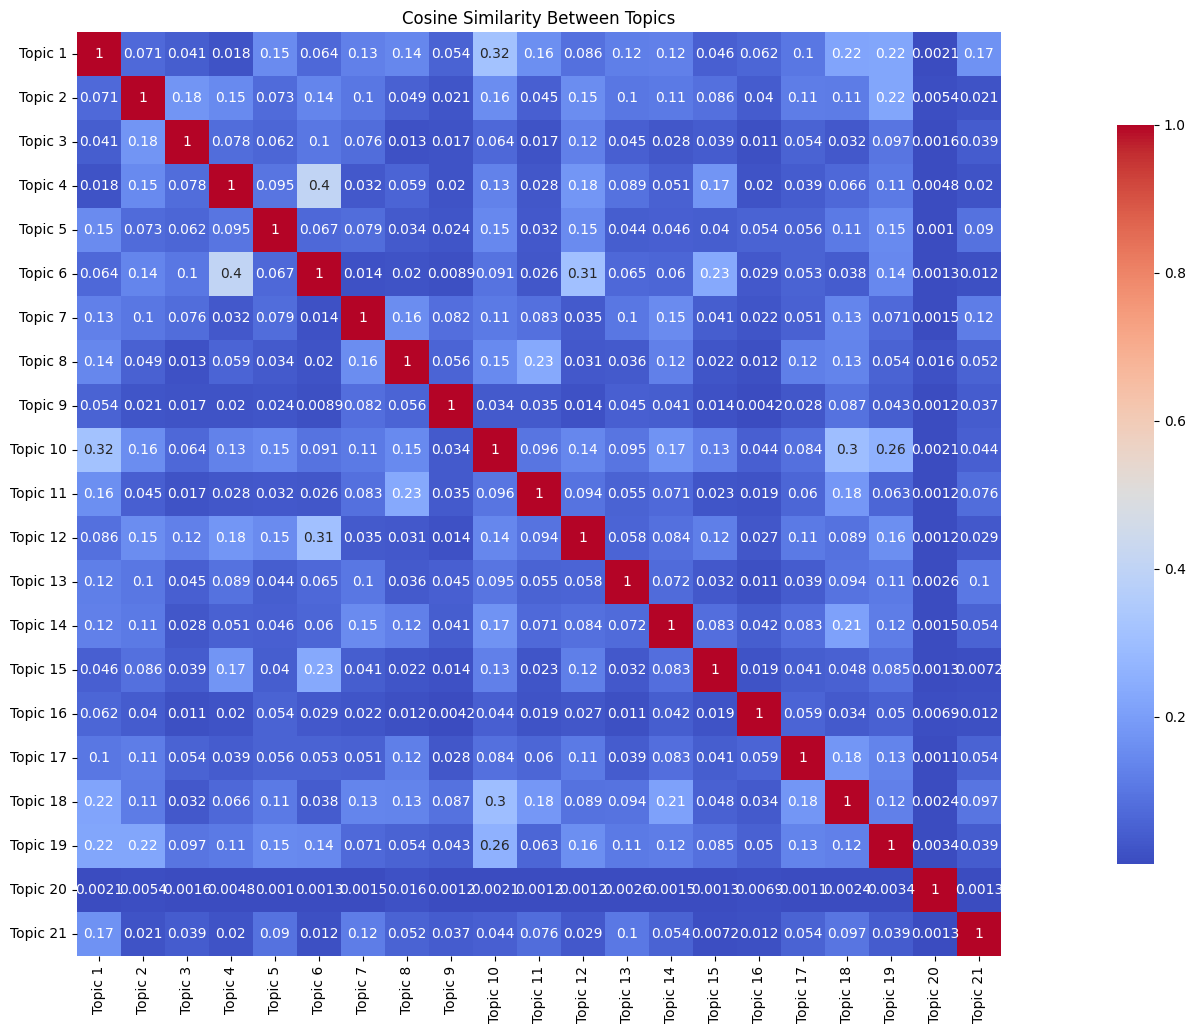

In [153]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt


topic_word_matrix = lda_model.get_topics()  # shape (num_topics, num_words)

cosine_sim_matrix = cosine_similarity(topic_word_matrix)

num_topics = lda_model.num_topics
topic_labels = ['Topic ' + str(i + 1) for i in range(num_topics)]
cosine_sim_df = pd.DataFrame(cosine_sim_matrix, index=topic_labels, columns=topic_labels)

plt.figure(figsize=(30, 12))
sns.heatmap(cosine_sim_df, annot=True, cmap="coolwarm", square=True, cbar_kws={"shrink": .8})
plt.title("Cosine Similarity Between Topics")
plt.show()




> **Densdrogram**

This code performs hierarchical clustering on topics generated by an LDA model, visualizing the clustering structure with a dendrogram to explore topic similarities. First, it extracts the topic-word distributions from the LDA model, where each topic is represented as a vector of word weights. Using these vectors, it calculates the cosine similarity between topics, quantifying how similar each topic pair is. Then, it converts the similarity values to a distance matrix (by subtracting similarity values from 1), as hierarchical clustering requires a measure of distance.

The code uses the Ward linkage method, a common choice in hierarchical clustering that minimizes the variance within clusters. This generates a linkage matrix, which is used to plot a dendrogram, illustrating how topics cluster based on their content similarity. Each topic is labeled on the x-axis, and the y-axis represents the "distance" or dissimilarity between clusters.
How to Interpret

*  Clustered Topics: Topics that merge at lower distances on the y-axis are more similar, indicating they share closely related themes. These clusters may represent broad themes in the corpus.
*  Higher-Level Clusters: Topics that join only at higher distances are less similar. Higher-level branches in the dendrogram represent broader distinctions between topics.
*  Practical Application: This visualization can help identify groups of related topics, suggesting which topics may be merged for a more cohesive model, or highlighting distinct themes for interpretation.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


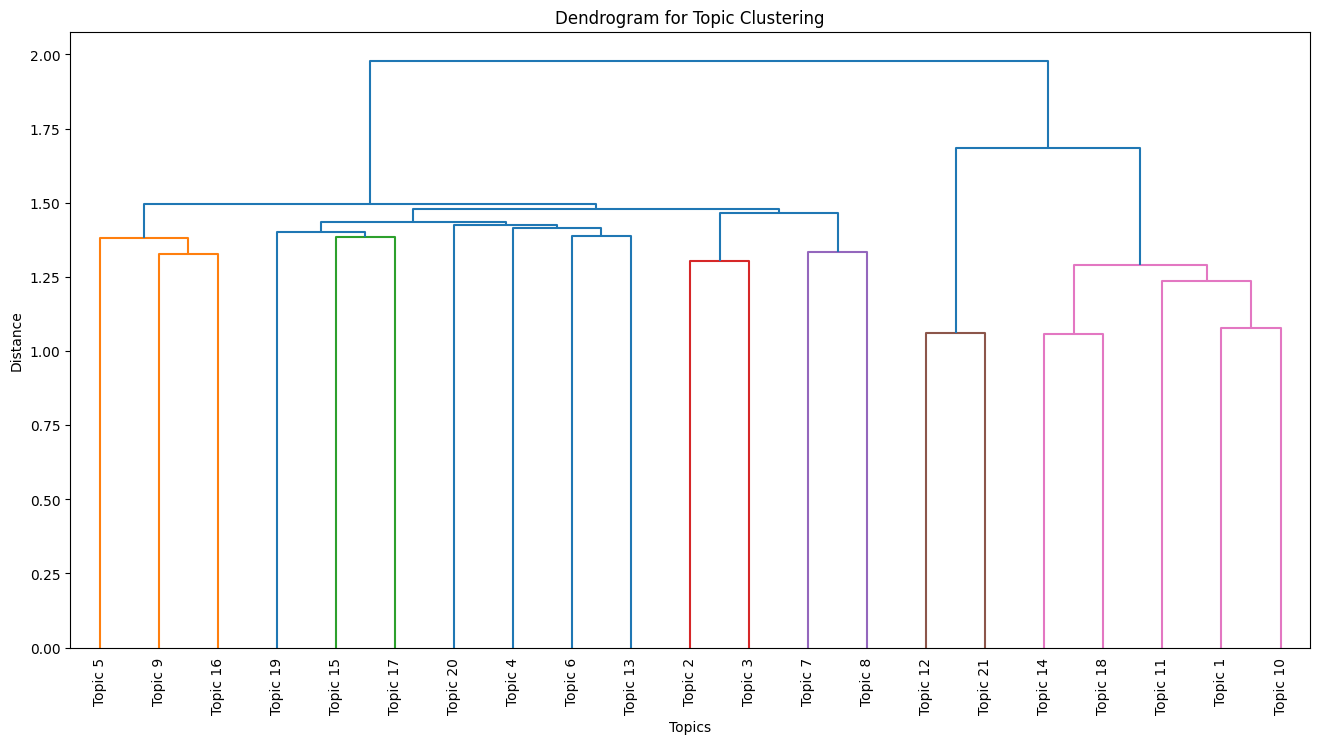

In [130]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt


topic_word_matrix = lda_model.get_topics()

cosine_sim_matrix = cosine_similarity(topic_word_matrix)


# Distance = 1 - similarity
distance_matrix = 1 - cosine_sim_matrix


linkage_matrix = linkage(distance_matrix, method='ward')

plt.figure(figsize=(16, 8))
dendrogram(linkage_matrix, labels=['Topic ' + str(i + 1) for i in range(lda_model.num_topics)], leaf_rotation=90)
plt.title("Dendrogram for Topic Clustering")
plt.xlabel("Topics")
plt.ylabel("Distance")
plt.show()




> **Inter Topic Distance Map**

This code uses the pyLDAvis library to create an interactive visualization for exploring the topics in an LDA model. The visualization provides a graphical interface for analyzing topic structures, term relevance, and document associations, making it especially useful for understanding the model's output in depth.


> **How to Interpret the Visualization**

*    Topic Bubbles: Each circle on the left represents a topic. The position of each bubble reflects the similarity between topics (closer bubbles indicate similar topics), while the size reflects the prevalence of the topic across the corpus.
*    Term Relevance: The right panel shows the top words for a selected topic. A slider allows adjusting between "relevance" and "frequency," helping to identify unique versus common terms.
*    Interactivity: Clicking on a topic bubble shows its term distributions and relevance, allowing you to explore how each topic is represented in the corpus and understand the dominant words for each topic.

This visualization helps in assessing topic quality, identifying overlaps, and gaining insights into the model's structure, providing a user-friendly way to explore complex topic relationships interactively.



In [131]:
#!pip install pyLDAvis
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis  # for newer gensim versions


pyLDAvis.enable_notebook()

lda_vis = gensimvis.prepare(lda_model, corpus, dictionary)
pyLDAvis.display(lda_vis)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


> **Document Clustering**

This code performs a comprehensive analysis of document clustering based on topic distributions from an LDA model. It begins by creating a Document-Topic Matrix, where each document is represented by its topic distribution as a probability vector. It then calculates the Cosine Similarity Matrix for the documents, which provides a measure of similarity between each pair of documents based on their topic distributions.

Next, the code applies K-means clustering to the Document-Topic Matrix, assigning each document to one of the predefined clusters. This clustering helps group documents with similar thematic content, which is especially useful for exploring large datasets.

For visualization, the code reduces the dimensionality of the Document-Topic Matrix to two dimensions in two ways:

*    PCA (Principal Component Analysis): The first plot shows documents projected into a 2D space with PCA, colored by cluster.
*    t-SNE (t-Distributed Stochastic Neighbor Embedding): The second plot uses t-SNE, which often preserves local structure better than PCA, making clusters more visually distinct.

How to Interpret the Results

*    Document Clusters: Documents with similar topic distributions are grouped into clusters. Each cluster may represent a distinct theme or set of related themes.
*    PCA vs. t-SNE: While PCA captures general trends in the data, t-SNE can reveal finer clustering patterns. Points of the same color in either plot represent documents in the same cluster.
*    Scatter Plot: Each point represents a document, and its position reflects its similarity to other documents based on topic distribution. Closer points indicate similar topic content, while separated clusters suggest distinct themes.

This analysis enables a deeper understanding of document similarities and thematic structures within the dataset, helping to identify coherent document groups and uncover underlying patterns.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


    Topic 1   Topic 2   Topic 3   Topic 4   Topic 5   Topic 6   Topic 7  \
0  0.016079  0.004175  0.003240  0.002275  0.006064  0.002266  0.006837   
1  0.098540  0.016758  0.001990  0.001372  0.003400  0.001366  0.004645   
2  0.035918  0.051633  0.003608  0.002527  0.029703  0.002516  0.007773   
3  0.025638  0.003295  0.002538  0.001779  0.298412  0.001774  0.135219   
4  0.273032  0.002689  0.062231  0.001459  0.003701  0.001454  0.022821   

    Topic 8   Topic 9  Topic 10  ...  Topic 12  Topic 13  Topic 14  Topic 15  \
0  0.004368  0.002134  0.013276  ...  0.415937  0.353176  0.070734  0.002438   
1  0.002632  0.036247  0.656453  ...  0.063885  0.002059  0.018312  0.001470   
2  0.004867  0.024972  0.083695  ...  0.458310  0.030256  0.065045  0.002708   
3  0.113886  0.001667  0.041671  ...  0.157091  0.002682  0.113596  0.001907   
4  0.002795  0.001368  0.265359  ...  0.251289  0.002193  0.061926  0.001564   

   Topic 16  Topic 17  Topic 18  Topic 19  Topic 20  Topic 21  
0  0

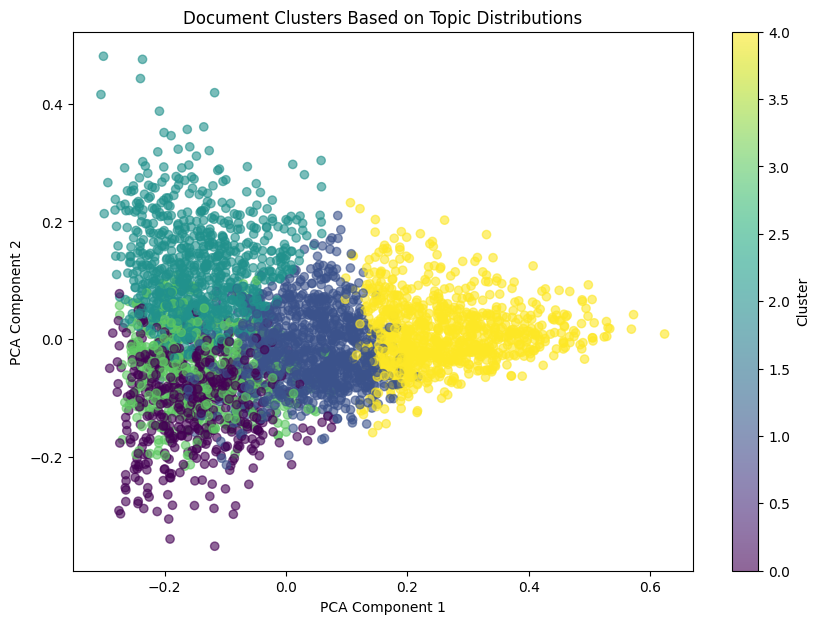

/usr/local/lib/python3.10/dist-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


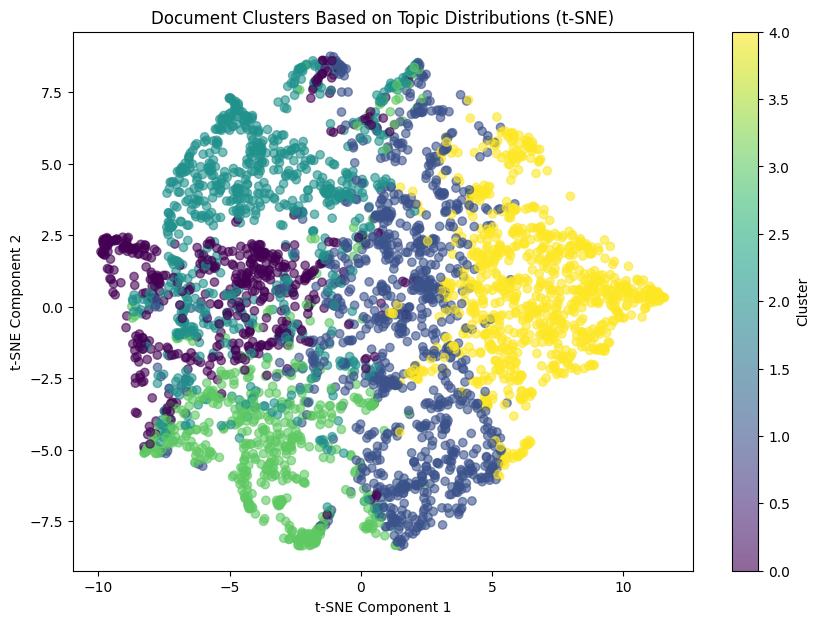

In [132]:
import numpy as np
import pandas as pd

doc_topic_matrix = []

for doc in corpus:

    topic_probs = lda_model.get_document_topics(doc, minimum_probability=0.0)

    topic_vector = [prob for _, prob in topic_probs]
    doc_topic_matrix.append(topic_vector)


doc_topic_df = pd.DataFrame(doc_topic_matrix, columns=[f'Topic {i+1}' for i in range(lda_model.num_topics)])

print(doc_topic_df.head())
from sklearn.metrics.pairwise import cosine_similarity

doc_similarity_matrix = cosine_similarity(doc_topic_df)
doc_similarity_df = pd.DataFrame(doc_similarity_matrix, index=doc_topic_df.index, columns=doc_topic_df.index)

print(doc_similarity_df.head())
from sklearn.cluster import KMeans


num_clusters = 5

kmeans = KMeans(n_clusters=num_clusters, random_state=42)
doc_topic_df['Cluster'] = kmeans.fit_predict(doc_topic_df)

print(doc_topic_df[['Cluster']].head())
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
doc_topic_2d = pca.fit_transform(doc_topic_df.drop(columns=['Cluster']))


plt.figure(figsize=(10, 7))
scatter = plt.scatter(doc_topic_2d[:, 0], doc_topic_2d[:, 1], c=doc_topic_df['Cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Cluster')
plt.title("Document Clusters Based on Topic Distributions")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=300)
doc_topic_2d_tsne = tsne.fit_transform(doc_topic_df.drop(columns=['Cluster']))

plt.figure(figsize=(10, 7))
scatter = plt.scatter(doc_topic_2d_tsne[:, 0], doc_topic_2d_tsne[:, 1], c=doc_topic_df['Cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Cluster')
plt.title("Document Clusters Based on Topic Distributions (t-SNE)")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()


In [135]:
import pandas as pd
import pymannkendall as mk


file_path = '/content/topic_trends_over_time.xlsx'  # Replace with your actual file path
data = pd.read_excel(file_path)


results = []

for column in data.columns:

    test_result = mk.original_test(data[column].dropna())  # Remove NaNs if any


    results.append({
        'Variable': column,
        'Trend': test_result.trend,
        'h': test_result.h,
        'p-value': test_result.p,
        'Z': test_result.z,
        'Tau': test_result.Tau,
        'S': test_result.s,
        'Var(S)': test_result.var_s,
        'Sen\'s Slope': test_result.slope,
        'Intercept': test_result.intercept
    })

results_df = pd.DataFrame(results)

results_df.to_excel('/content/MannKendall_Test_Results.xlsx', index=False)

print(results_df)

    Variable       Trend      h       p-value         Z       Tau      S  \
0       Year  increasing   True  8.842393e-11  6.485524  1.000000  231.0   
1    Topic 1  increasing   True  1.785429e-02  2.368626  0.367965   85.0   
2    Topic 2    no trend  False  9.101957e-01  0.112792  0.021645    5.0   
3    Topic 3  increasing   True  1.785429e-02  2.368626  0.367965   85.0   
4    Topic 4    no trend  False  2.839351e-01  1.071521  0.168831   39.0   
5    Topic 5  decreasing   True  2.799099e-03 -2.988981 -0.463203 -107.0   
6    Topic 6  increasing   True  2.784676e-02  2.199439  0.341991   79.0   
7    Topic 7    no trend  False  2.593549e-01  1.127917  0.177489   41.0   
8    Topic 8    no trend  False  1.945951e-01  1.297105  0.203463   47.0   
9    Topic 9    no trend  False  3.975874e-01  0.845938  0.134199   31.0   
10  Topic 10    no trend  False  1.143168e-01  1.579084  0.246753   57.0   
11  Topic 11  increasing   True  3.210967e-02  2.143043  0.333333   77.0   
12  Topic 12

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


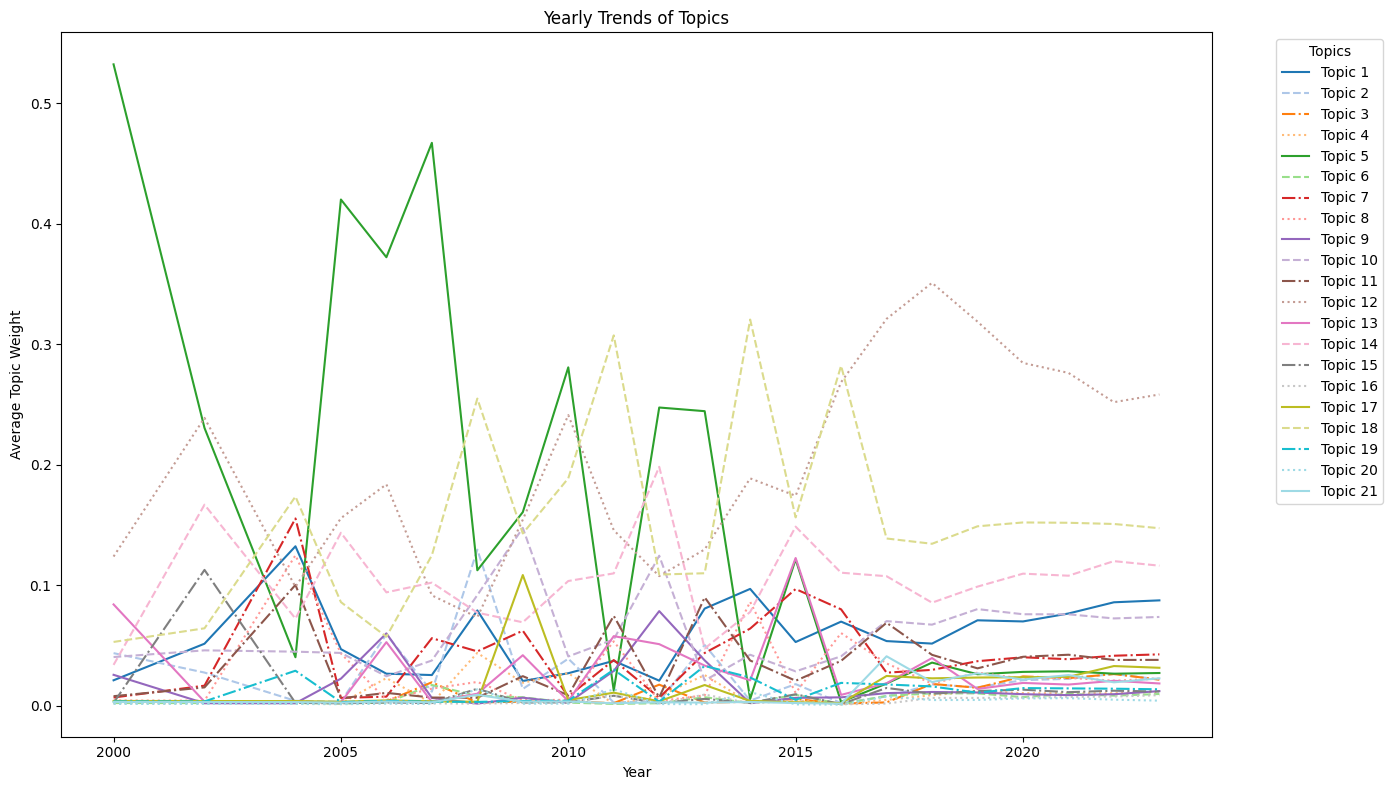

In [137]:
import matplotlib.pyplot as plt
import numpy as np

yearly_trends = df_weights.groupby('Year').mean()


line_styles = ['-', '--', '-.', ':'] * (len(yearly_trends.columns) // 4 + 1)
colors = plt.cm.tab20(np.linspace(0, 1, len(yearly_trends.columns)))

plt.figure(figsize=(14, 8))
for i, column in enumerate(yearly_trends.columns):
    plt.plot(yearly_trends.index, yearly_trends[column], label=column,
             linestyle=line_styles[i % len(line_styles)], color=colors[i])

plt.xlabel('Year')
plt.ylabel('Average Topic Weight')
plt.title('Yearly Trends of Topics')
plt.legend(title='Topics', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
